# 03. Componente Predictivo Dual (Valor Agregado)

**Enfoque metodológico:**
- **Partición estrictamente cronológica** (sin fuga de datos del futuro): Entrenamiento `2015-05` a `2024-06` (110 meses) y Prueba `2024-07` a `2026-09` (27 meses), complementado con validación `TimeSeriesSplit(5)`.
- **Modelo 1 – Regresión (Principal):** Predicción de la variación porcentual mensual de la canasta fresca de Popayán comparando `Baseline Estacional`, `Ridge (L2)`, `RandomForestRegressor` y `HistGradientBoosting`.
- **Modelo 2 – Clasificación (Complementario):** Alerta temprana binaria de *encarecimiento acelerado* (superar el percentil 75 de entrenamiento = **+4.65 %/mes**) comparando `LogisticRegression` y `RandomForestClassifier`.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
ROOT = Path('..') if Path('../models').exists() else Path('.')
MODELS_DIR = ROOT / 'models'

metrics = json.loads((MODELS_DIR / 'metrics_summary.json').read_text(encoding='utf-8'))
preds = pd.read_csv(MODELS_DIR / 'predictions_test.csv', parse_dates=['fecha'])

print('Entrenamiento:', metrics['train_range'], f"({metrics['train_rows']} meses)")
print('Prueba:', metrics['test_range'], f"({metrics['test_rows']} meses)")
print('Umbral alerta P75 (solo train):', f"{metrics['umbral_alerta_train_p75_pct']:.2f}%")

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\sagov\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


Entrenamiento: ['2015-05-01', '2024-06-01'] (110 meses)
Prueba: ['2024-07-01', '2026-09-01'] (27 meses)
Umbral alerta P75 (solo train): 4.65%


## 1. Comparativa de Modelos de Regresión

,test_mae,test_rmse,test_r2,test_sign_acc_pct,cv_mae,cv_rmse
Baseline Estacional,3.152,3.877,-0.198,66.7,NaN,NaN
Ridge (L2),2.805,3.674,-0.076,66.7,4.604,6.534
RandomForestRegressor,2.990,3.707,-0.096,55.6,4.229,6.126
HistGradientBoosting,3.042,4.050,-0.308,70.4,4.616,6.437


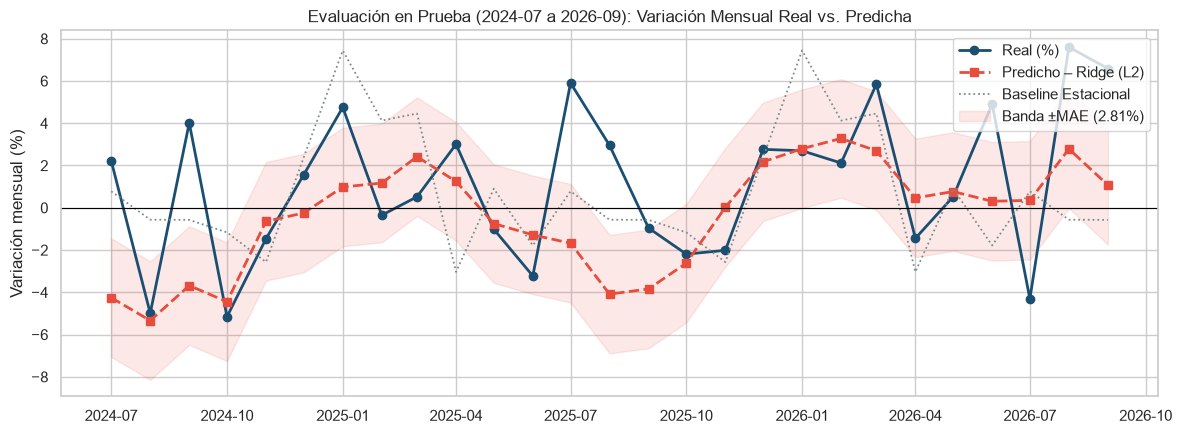

In [2]:
reg_tbl = pd.DataFrame(metrics['regression']['models']).T
display(reg_tbl)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(preds['fecha'], preds['var_mensual_real'], marker='o', lw=2, color='#1b4f72', label='Real (%)')
ax.plot(preds['fecha'], preds['var_mensual_pred'], marker='s', lw=2, ls='--', color='#e74c3c', label=f"Predicho – {metrics['regression']['best_model']}")
ax.plot(preds['fecha'], preds['var_mensual_baseline'], lw=1.3, ls=':', color='#7f8c8d', label='Baseline Estacional')
mae = metrics['regression']['models'][metrics['regression']['best_model']]['test_mae']
ax.fill_between(preds['fecha'], preds['var_mensual_pred'] - mae, preds['var_mensual_pred'] + mae, color='#e74c3c', alpha=0.12, label=f'Banda ±MAE ({mae:.2f}%)')
ax.axhline(0, color='black', lw=0.8)
ax.set_title('Evaluación en Prueba (2024-07 a 2026-09): Variación Mensual Real vs. Predicha')
ax.set_ylabel('Variación mensual (%)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 2. Importancia de Variables (Señal Climática vs. Estacionalidad)

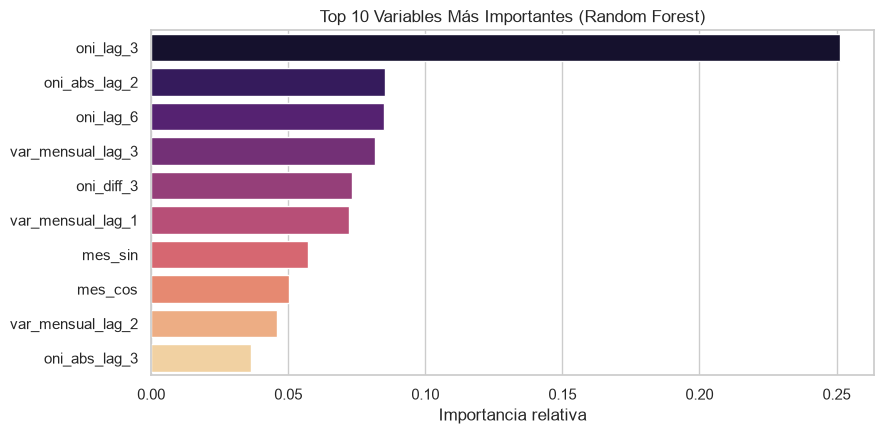

In [3]:
imp_df = pd.DataFrame(metrics['feature_importances_rf']).head(10)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=imp_df, x='importance', y='feature', palette='magma', hue='feature', legend=False, ax=ax)
ax.set_title('Top 10 Variables Más Importantes (Random Forest)')
ax.set_xlabel('Importancia relativa')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

## 3. Modelo Complementario de Clasificación (Alerta de Encarecimiento Acelerado)

,test_f1,test_precision,test_recall,test_accuracy,test_roc_auc
LogisticRegression,0.462,0.429,0.500,0.741,0.698
RandomForestClassifier,0.444,0.667,0.333,0.815,0.746


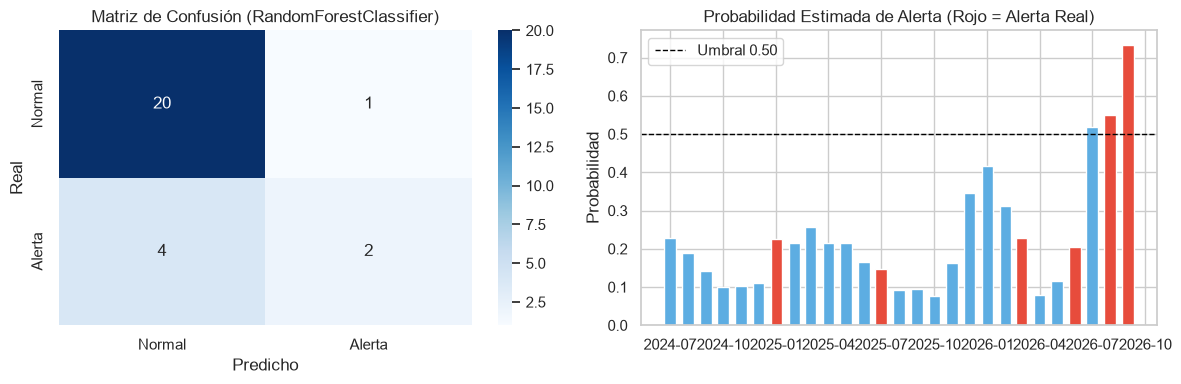

In [4]:
clf_tbl = pd.DataFrame({k: {m: v for m, v in d.items() if m != 'confusion_matrix'} for k, d in metrics['classification']['models'].items()}).T
display(clf_tbl)

best_clf = metrics['classification']['best_model']
cm = np.array(metrics['classification']['models'][best_clf]['confusion_matrix'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Alerta'], yticklabels=['Normal', 'Alerta'], ax=axes[0])
axes[0].set_title(f'Matriz de Confusión ({best_clf})')
axes[0].set_xlabel('Predicho')
axes[0].set_ylabel('Real')

axes[1].bar(preds['fecha'], preds['alerta_prob'], width=20, color=np.where(preds['alerta_real']==1, '#e74c3c', '#5dade2'))
axes[1].axhline(0.5, color='black', ls='--', lw=1, label='Umbral 0.50')
axes[1].set_title('Probabilidad Estimada de Alerta (Rojo = Alerta Real)')
axes[1].set_ylabel('Probabilidad')
axes[1].legend()
plt.tight_layout()
plt.show()

## 4. Limitaciones y Lectura Responsable de Resultados

- **No son certezas determinísticas:** El `MAE` de **2.81 %** en prueba refleja la volatilidad inherente de los alimentos perecederos en Popayán; las predicciones deben leerse como rangos de riesgo.
- **Variables exógenas no incluidas:** El modelo solo usa señales del índice ONI, rezagos y estacionalidad. Choques locales como bloqueos en la Vía Panamericana, precio del combustible, fertilizantes o inflación general explican la varianza residual.
- **Utilidad práctica:** Superar al baseline estacional en regresión (`-11 %` MAE) y lograr un `ROC-AUC = 0.746` en alertas tempranas demuestra que incorporar la dinámica y magnitud del ciclo ENSO aporta señal predictiva útil para seguimiento agroalimentario.